# 03 · Semantic IDs with k-means

Milestone 3 of the hands-on track. A **Semantic ID** replaces an item's arbitrary ID with a short tuple of discrete codes, e.g. `(17, 203, 88)`, so that similar items share prefixes and a generative model can decode items token by token (milestone 5).

Two k-means tokenizers (`src/genrec/tokenizers/kmeans.py`):
- **residual** (RQ-KMeans, as in OneRec): k-means on the embeddings, then on the residuals, level by level. One shared codebook per level, like RQ-VAE without a learned encoder.
- **hierarchical**: k-means, then k-means again inside each cluster. A code only means something under its parent.

Questions: how many items collide on the same ID, how evenly are codes used, do prefixes mean something, and how much retrieval signal survives quantization?

Needs `python scripts/embed_items.py` first.

In [1]:
import os
os.chdir('..')  # run from repo root

import json
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from genrec.data.amazon import load_processed
from genrec.data.sequences import leave_one_out
from genrec.embeddings.text import embeddings_path
from genrec.metrics import evaluate
from genrec.models.baselines import SemanticKNN
from genrec.tokenizers.kmeans import code_stats, hierarchical_kmeans, quantized_embeddings, residual_kmeans

sequences, items = load_processed('data/processed/beauty')
emb_full = np.load(embeddings_path('data/processed/beauty'))
emb = emb_full[1:]  # row i-1 = item i
train, valid, test = leave_one_out(sequences)

def knn_valid(item_emb):
    """Validation NDCG@10 of semantic kNN (default n_recent=5, decay=0.5) on the given item embeddings."""
    return evaluate(SemanticKNN(item_emb).recommend(valid[0], 10), valid[1], [10])['ndcg@10']

print('raw-embedding kNN, valid NDCG@10:', round(knn_valid(emb_full), 4))

raw-embedding kNN, valid NDCG@10: 0.0346


## Codebook size: collisions vs. fidelity
3 levels, K codes per level. `recon_cosine` is the cosine between an item's embedding and the quantized vector its codes stand for; `knn_ndcg@10` runs semantic kNN on those quantized vectors.

In [2]:
rows, built = [], {}
for method, build in [('residual', residual_kmeans), ('hierarchical', hierarchical_kmeans)]:
    for k in [32, 64, 128, 256]:
        codes, recon = build(emb, k, 3)
        built[method, k] = codes
        stats = code_stats(codes, emb, recon)
        rows.append({'method': method, 'K': k, **stats, 'knn_ndcg@10': knn_valid(quantized_embeddings(recon))})
sweep = pd.DataFrame(rows)
cols = ['method', 'K', 'unique_ids', 'collision_rate', 'max_group', 'l1_perplexity', 'l2_perplexity',
        'l3_perplexity', 'recon_cosine', 'knn_ndcg@10']
sweep[cols].round(4)

,method,K,unique_ids,collision_rate,max_group,l1_perplexity,l2_perplexity,l3_perplexity,recon_cosine,knn_ndcg@10
0,residual,32,7278,0.6111,26,29.8857,28.0264,27.7893,0.9558,0.0089
1,residual,64,9697,0.3322,15,57.0873,52.9147,48.6642,0.9612,0.0129
2,residual,128,10975,0.1665,14,115.3500,97.2415,87.8305,0.9658,0.0147
3,residual,256,11354,0.1143,6,228.4421,126.6325,49.3053,0.9690,0.0157
4,hierarchical,32,11971,0.0168,10,29.8857,31.6633,21.8431,0.9998,0.0306
5,hierarchical,64,12101,0.0000,1,57.0873,61.7506,7.2374,1.0001,0.0345
6,hierarchical,128,12101,0.0000,1,115.3500,116.3620,1.3885,1.0001,0.0345
7,hierarchical,256,12101,0.0000,1,228.4421,75.5239,1.0000,1.0001,0.0345


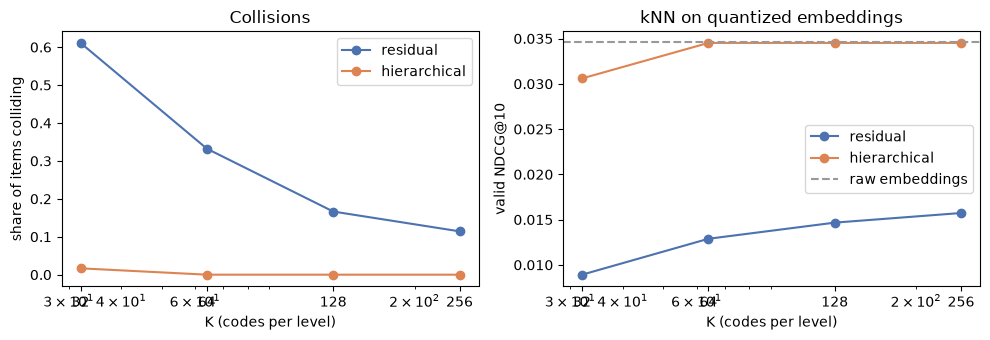

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
for method, color in [('residual', '#4C72B0'), ('hierarchical', '#DD8452')]:
    s = sweep[sweep.method == method]
    axes[0].plot(s.K, s.collision_rate, 'o-', color=color, label=method)
    axes[1].plot(s.K, s['knn_ndcg@10'], 'o-', color=color, label=method)
axes[1].axhline(knn_valid(emb_full), color='#999999', ls='--', label='raw embeddings')
axes[0].set(xscale='log', xlabel='K (codes per level)', ylabel='share of items colliding', title='Collisions')
axes[1].set(xscale='log', xlabel='K (codes per level)', ylabel='valid NDCG@10', title='kNN on quantized embeddings')
for ax in axes:
    ax.set_xticks([32, 64, 128, 256], ['32', '64', '128', '256'])
    ax.legend()
plt.tight_layout()
plt.show()

## How much does each residual level add?
Residual k-means with K=256, cutting the ID after 1–4 levels.

In [4]:
rows = []
for levels in [1, 2, 3, 4]:
    codes, recon = residual_kmeans(emb, 256, levels)
    stats = code_stats(codes, emb, recon)
    rows.append({'levels': levels, 'unique_ids': stats['unique_ids'], 'collision_rate': stats['collision_rate'],
                 'recon_cosine': stats['recon_cosine'], 'knn_ndcg@10': knn_valid(quantized_embeddings(recon))})
pd.DataFrame(rows).round(4)

,levels,unique_ids,collision_rate,recon_cosine,knn_ndcg@10
0,1,256,1.0000,0.9537,0.0084
1,2,7554,0.5911,0.9640,0.0139
2,3,11447,0.0978,0.9700,0.0172
3,4,11904,0.0316,0.9733,0.0173


Why does a 0.97 reconstruction cosine still lose so much? Compare the quantization error with how far apart an item's true neighbours are.

In [5]:
rng = np.random.default_rng(0)
sample = rng.choice(len(emb), 2000, replace=False)
sims = np.sort(emb[sample] @ emb.T, axis=1)[:, ::-1]  # column 0 is the item itself
_, recon = residual_kmeans(emb, 256, 3)
rc = (emb * recon).sum(1) / np.linalg.norm(recon, axis=1)
print(f'median cosine to 1st / 10th / 100th neighbour: '
      f'{np.median(sims[:, 1]):.3f} / {np.median(sims[:, 10]):.3f} / {np.median(sims[:, 100]):.3f}')
print(f'median cosine to own quantized vector (3x256): {np.median(rc):.3f}')

median cosine to 1st / 10th / 100th neighbour: 0.955 / 0.928 / 0.906
median cosine to own quantized vector (3x256): 0.970


## Do prefixes mean something?
**Category purity** of a prefix group = share of its items in the group's most common leaf category (item-weighted). Random grouping would give roughly the share of the largest category.

In [6]:
leaf = items['categories'].str.split(' \\| ').str[0].str.split(', ').str[-1].values

def purity(codes, depth):
    keys = pd.Series([tuple(c) for c in codes[:, :depth]])
    groups = pd.Series(leaf).groupby(keys)
    return groups.agg(lambda s: s.value_counts().iloc[0]).sum() / len(leaf)

rows = []
for key in [('residual', 32), ('residual', 256), ('hierarchical', 32), ('hierarchical', 256)]:
    codes = built[key]
    rows.append({'tokenizer': f'{key[0]} 3x{key[1]}', **{f'prefix {d}': purity(codes, d) for d in [1, 2, 3]}})
print(f'largest leaf category share: {pd.Series(leaf).value_counts(normalize=True).iloc[0]:.1%}')
pd.DataFrame(rows).set_index('tokenizer').round(3)

largest leaf category share: 6.0%


,prefix 1,prefix 2,prefix 3
tokenizer,,,
residual 3x32,0.419,0.488,0.810
residual 3x256,0.573,0.841,0.978
hierarchical 3x32,0.419,0.651,0.998
hierarchical 3x256,0.573,1.000,1.000


In [7]:
codes = built['residual', 256]
for c in rng.choice(256, 2, replace=False):
    members = np.where(codes[:, 0] == c)[0]
    print(f'\nlevel-1 code {c}: {len(members)} items, top leaf categories:',
          dict(Counter(leaf[members]).most_common(3)))
    for i in rng.choice(members, min(5, len(members)), replace=False):
        print('   ', items['title'].iloc[i][:90])


level-1 code 189: 60 items, top leaf categories: {'Eau de Toilette': 46, 'Lotions': 7, 'Eau de Parfum': 6}
    Nina By Nina Ricci For Women. Eau De Toilette Spray 2.7-Ounces
    Jean Nate by Revlon After Bath Splash 30 oz for Women
    Diamonds and Sapphires by Elizabeth Taylor for Women, Eau De Toilette Spray, 3.3-Ounce
    Charlie Red by Revlon for Women, Eau De Toilette Spray, 3.4 Ounce
    Curve Wave by Liz Claiborne for Women 3.4 oz Eau de Toilette Spray

level-1 code 3: 108 items, top leaf categories: {'Skin Protection': 27, 'Sports': 25, 'Lotions': 14}
    Neocutis Journee Biorestorative Day Cream with SPF 30, 1-Ounce Bottle
    Kiss My Face Face Factor Sun Screen for Face and Neck, SPF 30, 2 Ounce Tube
    Glytone Retexturize Body Lotion SPF 15, 12-Ounce Package
    Neutrogena Age Shield Face Sunblock Spf 70 - 3 oz.
    All Terrain KidSport SPF30 Oxybenzone-Free Natural Sunscreen, Disney Phineas and Ferb Pack


## What collides?
The largest groups of items sharing a full residual 3×256 ID.

In [8]:
groups = Counter(map(tuple, codes))
for key, size in groups.most_common(3):
    members = np.where((codes == key).all(1))[0]
    print(f'\nID {key}: {size} items')
    for i in members:
        print('   ', items['title'].iloc[i][:90])


ID (np.int32(66), np.int32(116), np.int32(94)): 6 items
    Red Cherry False Eyelashes #82 (Packs of 6)
    Red Cherry #138 False Eyelashes (Pack of 6 Pairs)
    Red Cherry #43 False Eyelashes (Pack of 6 Pairs)
    Red Cherry #WSP False Eyelashes (Pack of 6 Pairs)
    Red Cherry #117 False Eyelashes (Pack of 6)
    Red Cherry #43 False Eyelashes (Pack of 12 Pairs)

ID (np.int32(73), np.int32(5), np.int32(5)): 6 items
    China Glaze Nail Polish, Nova, 0.5 Fluid Ounce
    China Glaze Nail Polish, Westside Warrior, 0.5 Fluid Ounce
    China Glaze Nail Polish, Exotic Encounters, 0.5 Fluid Ounce
    China Glaze Nail Polish, Street Chic, 0.5 Fluid Ounce
    China Glaze Nail Lacquer, Escaping Reality, 0.5 Fluid Ounce
    China Glaze Nail Lacquer, Are You Jelly?, 0.5 Fluid Ounce

ID (np.int32(133), np.int32(5), np.int32(103)): 5 items
    China Glaze Nail Polish, Jetstream, 0.5 Fluid Ounce
    China Glaze Nail Polish, Skyscraper, 0.5 Fluid Ounce
    China Glaze Nail Polish, Concrete Catwalk,

## Results so far
Test-split metrics from the latest `scripts/train.py` run of each config. `semantic_knn_rqkmeans_beauty` runs semantic kNN on the residual 3×256 quantized embeddings.

In [9]:
def latest(name):
    run = sorted(Path('experiments').glob(f'{name}-*'))[-1]
    return json.loads((run / 'metrics.json').read_text())['test']

names = {
    'Popularity': 'popularity_beauty',
    'Semantic kNN (quantized, RQ-KMeans 3x256)': 'semantic_knn_rqkmeans_beauty',
    'Semantic kNN (raw embeddings)': 'semantic_knn_beauty',
    'SASRec': 'sasrec_beauty',
}
pd.DataFrame({label: latest(n) for label, n in names.items()}).T[
    ['recall@10', 'ndcg@10', 'recall@20', 'ndcg@20', 'mrr']
].round(4)

,recall@10,ndcg@10,recall@20,ndcg@20,mrr
Popularity,0.0114,0.0053,0.0195,0.0073,0.0040
"Semantic kNN (quantized, RQ-KMeans 3x256)",0.0302,0.0156,0.0470,0.0198,0.0124
Semantic kNN (raw embeddings),0.0593,0.0350,0.0790,0.0400,0.0290
SASRec,0.0753,0.0423,0.1077,0.0505,0.0346


## Takeaways
- **Prefixes carry meaning.** With residual 3×256, 57% of items match their level-1 group's majority leaf category and 84% at level 2 (largest category alone: 6%). Level-1 clusters read like product types (fragrances, SPF products). This shared structure is what lets a generative model generalize across items.
- **Collisions are near-duplicates.** The largest residual 3×256 collision groups are false-eyelash numbers and nail-polish shades from one brand, whose texts differ by a shade name. More levels or a bigger K only partly help; the text itself can't tell them apart. TIGER's extra collision code (in `scripts/build_semantic_ids.py`) handles them.
- **Quantization throws away fine ranking.** A 0.97 reconstruction cosine sounds high, but an item's nearest neighbour is at ~0.955, so the quantization error is as large as the gap between neighbours. kNN on quantized embeddings halves (test Recall@10 0.0593 → 0.0302). Semantic IDs are a coarse, shared vocabulary; the generative model in milestone 5 has to learn the fine-grained ranking from user sequences.
- **Residual vs. hierarchical.** Hierarchical k-means has almost no collisions and near-perfect reconstruction, but only by construction: once a cluster holds ≤ K items, its last level just numbers them (level-3 perplexity 7 → 1 as K grows). Those last codes carry no semantics and mean different things under each parent. Residual codes share meaning across parents and use all levels, so **residual 3×256 is the k-means baseline** to carry forward.
- **Diminishing returns per level.** With residual K=256, level 3 still pays off (collisions 59% → 10%, kNN NDCG@10 0.014 → 0.017), but level 4 mostly reduces collisions (to 3%) without improving kNN. Level-3 codebook usage is already low (perplexity ~49 of 256), since the residuals left at that depth are small.
- **Caveat: k-means is not bit-for-bit reproducible here.** Two identical residual 3×256 runs gave 11,354 vs 11,447 unique IDs and kNN NDCG@10 0.0157 vs 0.0172 (likely multithreaded k-means). Differences of that size between configurations shouldn't be over-read.
- **Next (milestone 4):** RQ-VAE learns the encoder jointly with the codebooks, which should spread usage across level-3 codes and reduce collisions. Compare it on these same tables.